# 1. ROUGHNECK CRUDE OIL - HYPOTHESIS DEFINITION & BASELINE BACKTEST
This notebook formulates the quantitative hypothesis and establishes the baseline backtest for the **Roughneck Crude Oil** system (LeBeau / Elden, 1999; TIS newsletter Vol. 03, Aug 2026) on **daily bars of an oil CFD** (hourly MT5 bars aggregated at the 17:00 New York close). Same structure as notebook 01 of the Monday Effect.

### 1.1 CORE QUANTITATIVE HYPOTHESIS
- **Trend + pullback exhaustion**: oil trends persist. In an established trend (SMA of lows above its slower SMA and rising, for longs) a close far above the recent 8-day low (1.5 ATR) marks a thrust that continues. Tested against the naked trigger in 4.1.
- **Entry on confirmation**: the buy stop sits at the highest high of the last 4 days, so we only enter if price keeps going the next day. Orders expire after one day.
- **Distance matters**: the farther the close is from the recent extreme (in ATRs), the stronger the thrust. Tested by quintiles in 4.2.
- **Symmetry (assumption)**: the published rules are long and short; the exits are only published for longs, so the short exits are the mirror image. Tested in 4.3.
- **Progressive exits protect gains and cut gap risk**: base stop $1 + tightening trail by ATR multiples. Tested against a plain $1 stop in 4.4.
- **Fat left tail from gaps**: the published system lost > $10,000 on single trades (April 2020). The hard limit and sizing are therefore part of the hypothesis (5.1) and the gap exposure is measured in 4.5.

### 1.2 FROZEN STRATEGY RULES
| Rule Component | Specification |
| :--- | :--- |
| **Instrument** | Oil CFD, daily bars closing 17:00 New York (built from MT5 H1) |
| **Uptrend** | `SMA10(low) > SMA20(low)` and `SMA20(low) - SMA20(low)[10 days ago] >= 0.25` (price units) |
| **Downtrend** | `SMA10(high) < SMA20(high)` and `SMA20(high)[10 days ago] - SMA20(high) >= 0.25` |
| **Long trigger** | `Close > LL(8) + 1.5 * ATR(45)` -> buy stop at `HH(4)` valid next day only |
| **Short trigger** | `Close < HH(3) - 2.0 * ATR(45)` -> sell stop at `LL(4)` valid next day only |
| **Base stop** | Entry -/+ $1.00 per barrel |
| **Early exit** | If days in trade < 4 and close is against the entry: stop at LL(5) (HH(5) for shorts) |
| **Trail (tightest stop wins)** | MaxTradeLow > entry + 2 ATR -> LL(4); > 4 ATR -> LL(2); > 5 ATR -> yesterday's low |
| **Lock** | If the max close >= entry + $1.00: stop at entry + $0.40 |
| **Gaps** | A stop crossed at the open fills at the open |
| **Entry bar** | Worst case (default `entry_bar_path="worst"`): if the entry bar's low (high for shorts) touches the base stop, we are stopped. The optimistic `ohlc` path heuristic is NOT used: on a $1 stop vs a ~$2 daily range it manufactures an edge (see placebo test in section 6) |
| **Costs** | Spread/commission in bps per side + swap per night (YAML) |

### 1.3 PROVENANCE & REFERENCE
TIS newsletter Vol. 03 (Aug 2026), TradeStation back-adjusted continuous CL, long and short, $200 round-trip cost: original 1988-1998: 59 trades, 78 % winners, PF 4.24; modern May 2001 - Jul 2026: 247 trades (~9.8 per year), 74 % winners, PF 1.81. This notebook does **not** reproduce that data: it tests the same rules on the CFD of this variant. Ambiguities resolved by assumption (all overridable in the YAML): short exits mirrored; `MaxTradeLow` = highest low since entry; ATR in the exits = ATR at the previous close; ATR is a simple average (`atr_method`, Wilder is tested in section 7).

### 1.4 STRATEGY PARAMETERS

In [1]:
# VARIANT = "v1_axi_usoil"
VARIANT = "v1_axi_wtifs"
# VARIANT = "v1_dwx_xtiusd"
HARD_LIMIT = 0.09
CAPITAL = 10_000.0

## 2. IMPORTS AND CONFIG

In [2]:
import os
import sys
import json
import importlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# ---- Paths ----
def find_upwards(name, start=None, must_be_dir=True):
    """Walk up from start (cwd by default) and return the first folder that contains `name`."""
    here = (start or Path.cwd()).resolve()
    for base in (here, *here.parents):
        target = base / name
        if target.is_dir() if must_be_dir else target.exists():
            return base
    raise FileNotFoundError(f"Could not find '{name}' walking up from {here}")

EDGE_DIR   = find_upwards('variants')                  # edge folder (notebooks, engine and variants/ live together)
utils_path = str(find_upwards('utils') / 'utils')      # research_development/utils
for p in (utils_path, str(EDGE_DIR)):
    if p not in sys.path:
        sys.path.insert(0, p)

from utils import compute_metrics
from metrics import sharpe_ratio, max_drawdown
import roughneck_engine as eng
import variant_config
from variant_config import load_variant, save_json

importlib.reload(eng)   # resets ENGINE_DEFAULTS: nothing leaks between variants

variant_config.EDGE_DIR = EDGE_DIR
assert (variant_config.EDGE_DIR / "variants").is_dir(), f"Doesn't exist {variant_config.EDGE_DIR / 'variants'}"

# ---- Variant config: single source of truth ----
cfg        = load_variant(VARIANT)
eng.set_engine_defaults(**cfg.get("engine_defaults", {}))
RUN_DIR    = cfg["run_dir"]
TICKER     = cfg["instrument"]["ticker"]
DATA_START = cfg["instrument"]["start"]
OOS_START  = cfg["oos_start_ts"]
P          = cfg["params"]
COST_BPS   = P["cost_bps_per_side"]
SIZE_FRAC  = eng.ENGINE_DEFAULTS["size_fraction"]
CONTRACT_SIZE, MIN_LOT, LOT_STEP = (eng.ENGINE_DEFAULTS[k] for k in ("contract_size", "min_lot", "lot_step"))
PPY        = 252    # daily bars, futures-like calendar: annualisation for Sharpe
MULTS      = [float(x) for x in cfg["grid"]["long_atr_mult_values"]]
ATR_LENS   = [int(x) for x in cfg["grid"]["atr_len_values"]]
CHOSEN     = (float(P["long_atr_mult"]), int(P["atr_len"]))

# Frozen rules, passed as-is to every backtest call. Indicator rules go to prepare(), the rest to the backtest.
RULES = dict(P)
RULES["mode"] = "fade"
IND   = {k: RULES[k] for k in eng.IND_KEYS}
def prep(df_raw, **over):
    """prepare() with the frozen indicator rules, optionally overriding some (e.g. atr_len, trend_mode)."""
    return eng.prepare(df_raw, **{**IND, **over})

# ---- Acceptance thresholds: every PASS / FAIL in this notebook is judged against these ----
PF_MIN, T_MIN, N_MIN = 1.3, 2.0, 60       # hypothesis: Profit Factor, t-stat of the mean trade, number of trades
N_OOS_MIN            = 20                 # minimum OOS trades to say anything
ALPHA                = 0.05               # significance level of the statistical tests
MIN_TRADES_PER_YEAR  = 3                  # every full calendar year should have at least this many trades
YEARS_POS_MIN        = 0.60               # share of full calendar years that must be profitable
MAX_GAP_LOSS_MULT    = 4.0                # worst single trade <= this many base stops
FULL_HISTORY_YEARS   = 10.0               # years of history behind N_MIN; shorter data scales N_MIN down (section 3)
REF_TRADES_PER_YEAR, REF_WIN, REF_PF = 9.8, 74.0, 1.81   # published modern period (informational, other instrument)

# ---- PASS / FAIL registry: each section registers its checks here, section 8 groups them ----
CHECKS = []

def check(section, name, passed, detail="", quiet=False):
    """Register one check. passed: True -> PASS, False -> FAIL, None -> SKIP (not applicable).
    Re-running a cell overwrites its previous entries instead of duplicating them."""
    status = "SKIP" if passed is None else ("PASS" if bool(passed) else "FAIL")
    entry = {"section": section, "name": name, "status": status, "detail": detail}
    for i, c in enumerate(CHECKS):
        if c["section"] == section and c["name"] == name:
            CHECKS[i] = entry
            break
    else:
        CHECKS.append(entry)
    if not quiet:
        print(f"   [{status}] {name}" + (f"  ->  {detail}" if detail else ""))
    return status

# ---- Style and helpers ----
BG, PANEL, GRIDC, TXT, SUB, GREEN, RED, ORANGE = "#15171c", "#1b1e26", "#2a2d37", "#e8e9ec", "#9aa0ab", "#34d399", "#f0555a", "#f5a524"
def dark_ax(ax):
    ax.set_facecolor(PANEL)
    ax.grid(color=GRIDC, alpha=0.8)
    ax.tick_params(colors=SUB)
    for s in ax.spines.values():
        s.set_visible(False)

# Oil regimes (an edge that only lives in one regime is a different edge): only the ones present in the data are used
ERAS_ALL = {"Pre-COVID (<=2019)": (1990, 2019), "COVID (2020)": (2020, 2020), "Post-COVID (2021+)": (2021, 2100)}
def era_of(y):
    return next(k for k, (a, b) in ERAS_ALL.items() if a <= y <= b)

def tstat(x):
    x = np.asarray(x, float)
    x = x[~np.isnan(x)]
    return float(x.mean() / (x.std(ddof=1) / np.sqrt(len(x)))) if len(x) > 2 and x.std(ddof=1) > 0 else np.nan


print("Imports complete.")
print(f"Loaded roughneck_engine from: {eng.__file__}")
print(f"Edge dir: {EDGE_DIR}")
print(f"Variant: {cfg['id']} | {TICKER} | long: trend + close > LL({P['long_low_n']}) + {P['long_atr_mult']:g} ATR({P['atr_len']}) | "
      f"short: close < HH({P['short_high_n']}) - {P['short_atr_mult']:g} ATR | stop ${P['stop_dollar']:g} | {COST_BPS:g} bps/side | size {SIZE_FRAC:.0%}")
print(f"Data source: {eng.ENGINE_DEFAULTS['data_source']} | swap: {eng.ENGINE_DEFAULTS['financing_bps_per_night']:g} bps/night | ATR method: {P['atr_method']}")
print(f"Run folder: {RUN_DIR}")
print(f"CFD: contract {CONTRACT_SIZE:g} bbl/lot | min lot {MIN_LOT:g} | step {LOT_STEP:g} | capital {CAPITAL:,.0f} | hard limit -{HARD_LIMIT:.0%}")

Imports complete.
Loaded roughneck_engine from: /Users/luyandy/Documents/Alphaca Capital/Alphaca-Capital-Research/research_development/02_strategy_development/Roughneck_Crude/roughneck_engine.py
Edge dir: /Users/luyandy/Documents/Alphaca Capital/Alphaca-Capital-Research/research_development/02_strategy_development/Roughneck_Crude
Variant: ROUGHNECK.wtifs.cfd.v1 | wtifs | long: trend + close > LL(8) + 1.5 ATR(45) | short: close < HH(3) - 2 ATR | stop $1 | 4 bps/side | size 100%
Data source: csv_h1 | swap: 1.5 bps/night | ATR method: sma
Run folder: /Users/luyandy/Documents/Alphaca Capital/Alphaca-Capital-Research/research_development/02_strategy_development/Roughneck_Crude/runs/v1_axi_wtifs
CFD: contract 1000 bbl/lot | min lot 0.01 | step 0.01 | capital 10,000 | hard limit -9%


## 3. LOAD DATA AND IN-SAMPLE / OUT-OF-SAMPLE

In [3]:
df_raw = eng.load_data(TICKER, start=DATA_START)
print(len(df_raw), "daily bars |", df_raw.index[0].date(), "->", df_raw.index[-1].date(), "| source:", eng.ENGINE_DEFAULTS["data_source"])
print(df_raw.groupby(df_raw.index.year).size().to_dict())

# Indicators are computed ONCE on the full history, so slicing IS/OOS keeps the warm-up
df = prep(df_raw)
n_is = int((df.index < OOS_START).sum())
df_is, df_oos = df.iloc[:n_is].copy(), df.iloc[n_is:].copy()
assert len(df_is) > 0 and len(df_oos) > 0, "Check oos_start_ts against the history of this ticker."
oos_start = df_oos.index[0]

_warm_end = df.index[df["warm"].to_numpy().argmax()]
_signal_years = (df.index[-1] - _warm_end).days / 365.25
if _signal_years < FULL_HISTORY_YEARS:
    N_MIN = max(20, int(round(N_MIN * _signal_years / FULL_HISTORY_YEARS)))

print("=" * 70)
print("DATA INGESTION & DATASET SPLIT")
print("=" * 70)
print(f"Total Prepared Bars: {len(df):,} ({df.index.min():%Y-%m-%d} to {df.index.max():%Y-%m-%d})")
print(f"In-Sample (IS, {len(df_is)/len(df)*100:.1f}%): {len(df_is):,} bars ({df_is.index.min():%Y-%m-%d} to {df_is.index.max():%Y-%m-%d})")
print(f"Out-of-Sample (OOS, {len(df_oos)/len(df)*100:.1f}%): {len(df_oos):,} bars ({df_oos.index.min():%Y-%m-%d} to {df_oos.index.max():%Y-%m-%d})")
print(f"Warm-up done on {_warm_end:%Y-%m-%d} | usable years: {_signal_years:.1f} | N_MIN = {N_MIN} | N_OOS_MIN = {N_OOS_MIN}")
print("=" * 70)

# ---- 3.1 DATA QUALITY & ROLLOVER (extra process: this edge lives on gaps and $1 stops, so bad data invalidates everything) ----
gap_usd = (df_raw["open"] - df_raw["close"].shift()).abs().dropna()
day_gap = df_raw.index.to_series().diff().dt.days.dropna()
bad_ohlc = ~((df_raw["high"] >= df_raw[["open", "close"]].max(axis=1)) & (df_raw["low"] <= df_raw[["open", "close"]].min(axis=1)))
print("\nCHECKS (section 3):")
check("3. Data", "IS and OOS are both non-empty", len(df_is) > 0 and len(df_oos) > 0, f"IS {len(df_is):,} bars | OOS {len(df_oos):,} bars")
check("3. Data", "Prices are strictly positive", bool((df_raw[["open", "high", "low", "close"]] > 0).all().all()),
      f"min close {df_raw['close'].min():.2f} (cash CFDs sometimes break on 2020-04-20)")
check("3. Data", "OHLC consistent (>= 99.9% of bars)", bad_ohlc.mean() <= 0.001, f"{int(bad_ohlc.sum())} inconsistent bars")
check("3. Data", "No calendar gap longer than 5 days (>= 99.5% of steps)", (day_gap <= 5).mean() >= 0.995, f"{int((day_gap > 5).sum())} gaps > 5 days")
check("3. Data", "Close-to-open jumps above 4 USD are rare (< 0.5% of bars): rollover jumps would show here",
      (gap_usd > 4.0).mean() < 0.005, f"{(gap_usd > 4.0).mean():.2%} of bars | largest {gap_usd.max():.2f}")
print("Ten largest close->open jumps (check whether they sit on contract-roll dates, typically around the 20th):")
display(gap_usd.nlargest(10).round(2).to_frame("jump_usd").assign(weekday=lambda x: x.index.day_name()))
df[["open", "high", "low", "close", "atr", "long_sig", "short_sig"]].tail()

4343 daily bars | 2010-01-04 -> 2026-11-02 | source: csv_h1
{2010: 258, 2011: 258, 2012: 258, 2013: 258, 2014: 258, 2015: 257, 2016: 258, 2017: 257, 2018: 258, 2019: 258, 2020: 259, 2021: 258, 2022: 258, 2023: 257, 2024: 259, 2025: 258, 2026: 216}
DATA INGESTION & DATASET SPLIT
Total Prepared Bars: 4,343 (2010-01-04 to 2026-11-02)
In-Sample (IS, 77.2%): 3,353 bars (2010-01-04 to 2022-12-30)
Out-of-Sample (OOS, 22.8%): 990 bars (2023-01-03 to 2026-11-02)
Warm-up done on 2010-03-05 | usable years: 16.7 | N_MIN = 60 | N_OOS_MIN = 20

CHECKS (section 3):
   [PASS] IS and OOS are both non-empty  ->  IS 3,353 bars | OOS 990 bars
   [PASS] Prices are strictly positive  ->  min close 12.91 (cash CFDs sometimes break on 2020-04-20)
   [PASS] OHLC consistent (>= 99.9% of bars)  ->  0 inconsistent bars
   [PASS] No calendar gap longer than 5 days (>= 99.5% of steps)  ->  0 gaps > 5 days
   [PASS] Close-to-open jumps above 4 USD are rare (< 0.5% of bars): rollover jumps would show here  ->  0.25% 

,jump_usd,weekday
2026-03-09,9.33,Monday
2020-03-09,8.82,Monday
2019-09-16,7.41,Monday
2026-03-02,7.21,Monday
2026-08-03,6.80,Monday
2022-03-07,6.70,Monday
2020-04-17,6.58,Friday
2026-07-27,5.00,Monday
2023-04-03,4.78,Monday
2026-04-20,4.59,Monday


,open,high,low,close,atr,long_sig,short_sig
2026-10-27,101.23,102.81,99.45,100.17,3.977333,False,False
2026-10-28,100.16,103.54,99.75,101.97,3.980667,True,False
2026-10-29,101.96,102.99,99.80,102.85,3.972000,True,False
2026-10-30,102.74,104.98,102.43,102.91,3.995333,True,False
2026-11-02,102.33,102.73,96.36,96.52,4.066667,False,False


## 4. EXPLORATORY CHECKS OF THE HYPOTHESIS (EDGE-SPECIFIC)
### 4.1 DOES THE TREND FILTER ADD VALUE? FULL RULES VS NAKED TRIGGER (NO TREND FILTER)

In [4]:
_present = {y for y in df_raw.index.year}
ERAS = {k: v for k, v in ERAS_ALL.items() if any(v[0] <= y <= v[1] for y in _present)}
print("Regimes with data:", list(ERAS))

df_naked = prep(df_raw, trend_mode="off")
tr_full  = eng.run_roughneck_backtest(df, **RULES)
tr_naked = eng.run_roughneck_backtest(df_naked, **{**RULES, "trend_mode": "off"})
for t in (tr_full, tr_naked):
    t["era"] = [era_of(y) for y in pd.to_datetime(t["entry_time"]).dt.year]

rows = []
for name, t in (("Naked trigger (no trend filter)", tr_naked), ("Configured (trend + trigger)", tr_full)):
    m = compute_metrics(t, 1.0, 0.0)
    rows.append({"Rules": name, "Trades": m["num_trades"], "Win %": round(m["win_rate"], 1), "PF": round(m["profit_factor"], 3),
                 "Mean net %": round(t["pnl"].mean(), 3), "t-stat": round(tstat(t["pnl"]), 2)})
tbl41 = pd.DataFrame(rows).set_index("Rules")
print("=" * 70)
print("TREND FILTER: NAKED TRIGGER VS CONFIGURED (net of costs, 100% capital)")
print("=" * 70)
display(tbl41)

print("\nCHECKS (4.1):")
a, b = tbl41.iloc[0], tbl41.iloc[1]
check("4.1 Trend filter", "Configured PF beats the naked trigger", b["PF"] > a["PF"], f"{b['PF']:.3f} vs {a['PF']:.3f}")
check("4.1 Trend filter", "Configured mean net per trade beats the naked trigger", b["Mean net %"] > a["Mean net %"],
      f"{b['Mean net %']:+.3f}% vs {a['Mean net %']:+.3f}%")
check("4.1 Trend filter", "The trend filter does not just cut trades: mean net per trade rises (not only fewer losers)",
      b["Mean net %"] > a["Mean net %"] and b["Trades"] < a["Trades"], f"{int(b['Trades'])} vs {int(a['Trades'])} trades")

Regimes with data: ['Pre-COVID (<=2019)', 'COVID (2020)', 'Post-COVID (2021+)']
TREND FILTER: NAKED TRIGGER VS CONFIGURED (net of costs, 100% capital)


,Trades,Win %,PF,Mean net %,t-stat
Rules,,,,,
Naked trigger (no trend filter),1683,43.9,0.671,-0.301,-7.5
Configured (trend + trigger),802,43.1,0.663,-0.298,-5.4



CHECKS (4.1):
   [FAIL] Configured PF beats the naked trigger  ->  0.663 vs 0.671
   [PASS] Configured mean net per trade beats the naked trigger  ->  -0.298% vs -0.301%
   [PASS] The trend filter does not just cut trades: mean net per trade rises (not only fewer losers)  ->  802 vs 1683 trades


'PASS'

### 4.2 DOES THE TRIGGER DISTANCE MATTER? ATR-DISTANCE QUINTILES

NET RETURN BY TRIGGER-DISTANCE QUINTILE (naked trigger, so the full range of distances is observed)


,Trades,dist_from,dist_to,net_mean,hit,net_t
quintile,,,,,,
Q1 near,337,1.501,1.795,-0.294,44.510,-3.154
Q2,336,1.796,2.131,-0.414,41.071,-4.613
Q3,337,2.131,2.463,-0.166,47.478,-1.834
Q4,336,2.464,3.060,-0.362,43.452,-4.030
Q5 far,337,3.060,10.047,-0.269,43.027,-3.168


Spearman rho (distance in ATR vs net return): -0.001 (p = 0.969)

CHECKS (4.2):
   [FAIL] Distance correlates positively with net return (p < 0.05)  ->  rho = -0.001, p = 0.969
   [PASS] Top quintile beats the bottom quintile  ->  -0.269% vs -0.294%


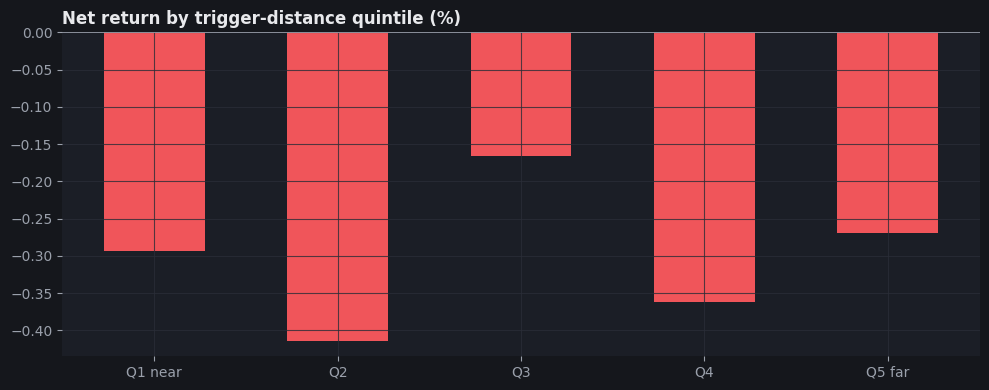

In [5]:
q = tr_naked.dropna(subset=["dist_atr"]).copy()
q["quintile"] = pd.qcut(q["dist_atr"], 5, labels=["Q1 near", "Q2", "Q3", "Q4", "Q5 far"], duplicates="drop")
qt = q.groupby("quintile", observed=True).agg(Trades=("pnl", "size"), dist_from=("dist_atr", "min"), dist_to=("dist_atr", "max"),
                                              net_mean=("pnl", "mean"), hit=("win", "mean"))
qt["net_t"] = q.groupby("quintile", observed=True)["pnl"].apply(tstat)
qt["hit"] *= 100
rho, p_rho = stats.spearmanr(q["dist_atr"], q["pnl"])
print("=" * 70)
print("NET RETURN BY TRIGGER-DISTANCE QUINTILE (naked trigger, so the full range of distances is observed)")
print("=" * 70)
display(qt.round(3))
print(f"Spearman rho (distance in ATR vs net return): {rho:+.3f} (p = {p_rho:.3f})")

print("\nCHECKS (4.2):")
check("4.2 Distance", f"Distance correlates positively with net return (p < {ALPHA:g})", rho > 0 and p_rho < ALPHA, f"rho = {rho:+.3f}, p = {p_rho:.3f}")
check("4.2 Distance", "Top quintile beats the bottom quintile", qt["net_mean"].iloc[-1] > qt["net_mean"].iloc[0],
      f"{qt['net_mean'].iloc[-1]:+.3f}% vs {qt['net_mean'].iloc[0]:+.3f}%")

fig, ax = plt.subplots(figsize=(10, 4), facecolor=BG)
dark_ax(ax)
ax.bar(range(len(qt)), qt["net_mean"], color=[GREEN if v > 0 else RED for v in qt["net_mean"]], width=0.55)
ax.axhline(0, color=SUB, lw=0.6)
ax.set_xticks(range(len(qt))); ax.set_xticklabels(qt.index, color=SUB)
ax.set_title("Net return by trigger-distance quintile (%)", color=TXT, fontweight="bold", loc="left")
plt.tight_layout(); plt.show()

### 4.3 LONG VS SHORT (THE SHORT EXITS ARE A MIRROR ASSUMPTION)

In [6]:
rows = []
for name, side in (("Long only", "long"), ("Short only", "short"), ("Both (configured)", "both")):
    t = eng.run_roughneck_backtest(df, **{**RULES, "side": side})
    m = compute_metrics(t, 1.0, 0.0)
    rows.append({"Side": name, "Trades": m["num_trades"], "Win %": round(m["win_rate"], 1), "PF": round(m["profit_factor"], 3),
                 "Mean net %": round(t["pnl"].mean(), 3), "t-stat": round(tstat(t["pnl"]), 2), "Net sum %": round(t["pnl"].sum(), 1)})
side_tbl = pd.DataFrame(rows).set_index("Side")
display(side_tbl)
print("Mean net by regime and side (configured rules):")
display(tr_full.pivot_table(index="era", columns="type", values="pnl", aggfunc=["mean", "size"]).reindex(list(ERAS)).round(3))

print("\nCHECKS (4.3):")
check("4.3 Sides", "Long side PF > 1", side_tbl.loc["Long only", "PF"] > 1.0, f"PF {side_tbl.loc['Long only', 'PF']:.3f}")
check("4.3 Sides", "Short side PF > 1 (the mirror assumption holds)", side_tbl.loc["Short only", "PF"] > 1.0, f"PF {side_tbl.loc['Short only', 'PF']:.3f}")
check("4.3 Sides", "Both sides together beat the better single side on net sum (diversifies)",
      side_tbl.loc["Both (configured)", "Net sum %"] >= side_tbl.loc[["Long only", "Short only"], "Net sum %"].max(),
      f"{side_tbl.loc['Both (configured)', 'Net sum %']:.1f}% vs best single side {side_tbl.loc[['Long only', 'Short only'], 'Net sum %'].max():.1f}%")

,Trades,Win %,PF,Mean net %,t-stat,Net sum %
Side,,,,,,
Long only,118,43.2,0.636,-0.413,-2.15,-48.7
Short only,684,43.1,0.669,-0.278,-4.99,-190.3
Both (configured),802,43.1,0.663,-0.298,-5.40,-239.0


Mean net by regime and side (configured rules):


mean        size      
type                 long  short long short
era                                        
Pre-COVID (<=2019) -0.087 -0.110   63   359
COVID (2020)       -1.949 -0.698   16    32
Post-COVID (2021+) -0.309 -0.439   39   293


CHECKS (4.3):
   [FAIL] Long side PF > 1  ->  PF 0.636
   [FAIL] Short side PF > 1 (the mirror assumption holds)  ->  PF 0.669
   [FAIL] Both sides together beat the better single side on net sum (diversifies)  ->  -239.0% vs best single side -48.7%


'FAIL'

### 4.4 DOES EACH EXIT COMPONENT ADD VALUE? ABLATION OF THE EXIT SET
A plain $1 stop never takes profit (the trade would run until the stop is hit), so the honest question is what each component adds: the early exit, the ATR trailing tiers and the $0.40 lock.

In [7]:
ABL_EXITS = {"Full exit set (configured)": {}, "No early exit": dict(use_early=False), "No ATR tiers": dict(use_tiers=False),
             "No lock at +$1": dict(use_lock=False), "Base stop only (reference)": dict(use_early=False, use_tiers=False, use_lock=False)}
rows, tr_ex = [], {}
for name, kw in ABL_EXITS.items():
    t = eng.run_roughneck_backtest(df, **{**RULES, **kw}); tr_ex[name] = t
    m = compute_metrics(t, 1.0, 0.0)
    w, l = t.loc[t.pnl > 0, "pnl"], t.loc[t.pnl <= 0, "pnl"]
    rows.append({"Exits": name, "Trades": m["num_trades"], "Win %": round(m["win_rate"], 1), "PF": round(m["profit_factor"], 3),
                 "Mean net %": round(t["pnl"].mean(), 3), "Avg win %": round(w.mean(), 3), "Avg loss %": round(l.mean(), 3), "Avg bars": round(t["bars"].mean(), 1)})
ex_tbl = pd.DataFrame(rows).set_index("Exits")
display(ex_tbl)
print(tr_full["exit_reason"].value_counts().to_dict())

print("\nCHECKS (4.4):")
full = ex_tbl.loc["Full exit set (configured)"]
for comp, label in (("No early exit", "early exit"), ("No ATR tiers", "ATR trailing tiers"), ("No lock at +$1", "lock at +$1")):
    check("4.4 Exits", f"The {label} adds value (full set PF >= without it)", full["PF"] >= ex_tbl.loc[comp, "PF"], f"{full['PF']:.3f} vs {ex_tbl.loc[comp, 'PF']:.3f}")

,Trades,Win %,PF,Mean net %,Avg win %,Avg loss %,Avg bars
Exits,,,,,,,
Full exit set (configured),802,43.1,0.663,-0.298,1.357,-1.554,1.4
No early exit,802,43.1,0.663,-0.298,1.357,-1.554,1.4
No ATR tiers,802,43.1,0.663,-0.298,1.357,-1.554,1.4
No lock at +$1,802,43.1,0.663,-0.298,1.357,-1.554,1.4
Base stop only (reference),802,43.1,0.663,-0.298,1.357,-1.554,1.4


{'target': 345, 'stop_entry_bar': 342, 'stop': 108, 'time': 5, 'gap_stop': 2}

CHECKS (4.4):
   [PASS] The early exit adds value (full set PF >= without it)  ->  0.663 vs 0.663
   [PASS] The ATR trailing tiers adds value (full set PF >= without it)  ->  0.663 vs 0.663
   [PASS] The lock at +$1 adds value (full set PF >= without it)  ->  0.663 vs 0.663


### 4.5 GAP RISK: HOW BAD CAN A SINGLE TRADE GET?

In [8]:
base_pct = RULES["stop_dollar"] / tr_full["entry_price"].mean() * 100
worst = tr_full.nsmallest(5, "pnl")[["entry_time", "type", "entry_price", "exit_price", "pnl", "pnl_usd", "exit_reason"]]
print(f"Average base stop = {base_pct:.2f}% of price. Five worst trades:")
display(worst.round(3))
gap_share = float((tr_full["exit_reason"] == "gap_stop").mean())
print(f"Exits through a gap: {gap_share:.1%} | worst adverse excursion on the full history: ${eng.worst_adverse_move(df, tr_full):.2f}/bbl")

print("\nCHECKS (4.5):")
check("4.5 Gaps", f"Worst trade loses <= {MAX_GAP_LOSS_MULT:g} base stops", -tr_full["pnl"].min() <= MAX_GAP_LOSS_MULT * base_pct,
      f"worst {tr_full['pnl'].min():.2f}% vs {MAX_GAP_LOSS_MULT * base_pct:.2f}% allowed")
check("4.5 Gaps", "Gap exits are a minority of exits (< 15%)", gap_share < 0.15, f"{gap_share:.1%}")

Average base stop = 1.32% of price. Five worst trades:


,entry_time,type,entry_price,exit_price,pnl,pnl_usd,exit_reason
438,2020-04-22,long,13.04,12.04,-7.749,-1.00,stop_entry_bar
439,2020-04-23,long,14.43,13.43,-7.010,-1.00,stop_entry_bar
437,2020-04-15,long,20.69,19.69,-4.913,-1.00,stop_entry_bar
436,2020-03-19,long,22.75,21.75,-4.476,-1.00,stop_entry_bar
302,2016-12-09,short,50.91,52.79,-3.818,-1.88,gap_stop


Exits through a gap: 0.2% | worst adverse excursion on the full history: $18.72/bbl

CHECKS (4.5):
   [FAIL] Worst trade loses <= 4 base stops  ->  worst -7.75% vs 5.26% allowed
   [PASS] Gap exits are a minority of exits (< 15%)  ->  0.2%


'PASS'

## 5. BASELINE BACKTEST WITH FROZEN RULES

PERFORMANCE SUMMARY (NET OF 4 BPS PER SIDE + SWAP · daily MTM drawdown, Sharpe annualised x252)


,Period,Sizing,Trades,Win Rate,Profit Factor,Expectancy,Total Return,CAGR,Sharpe,Max Drawdown
0,In-Sample (2010-2022),100% Capital,621,44.6%,0.693,-0.276%,-83.5%,-12.9%,-1.14,-85.61%
1,In-Sample (2010-2022),100% Capital (robot),621,44.6%,0.693,-0.276%,-83.5%,-12.9%,-1.14,-85.61%
2,Out-of-Sample (2023-2026),100% Capital,181,38.1%,0.550,-0.373%,-49.9%,-16.5%,-1.94,-50.36%
3,Out-of-Sample (2023-2026),100% Capital (robot),181,38.1%,0.550,-0.373%,-49.9%,-16.5%,-1.94,-50.36%
4,Full Period (2010-2026),100% Capital,802,43.1%,0.663,-0.298%,-91.7%,-13.8%,-1.28,-92.86%
5,Full Period (2010-2026),100% Capital (robot),802,43.1%,0.663,-0.298%,-91.7%,-13.8%,-1.28,-92.86%


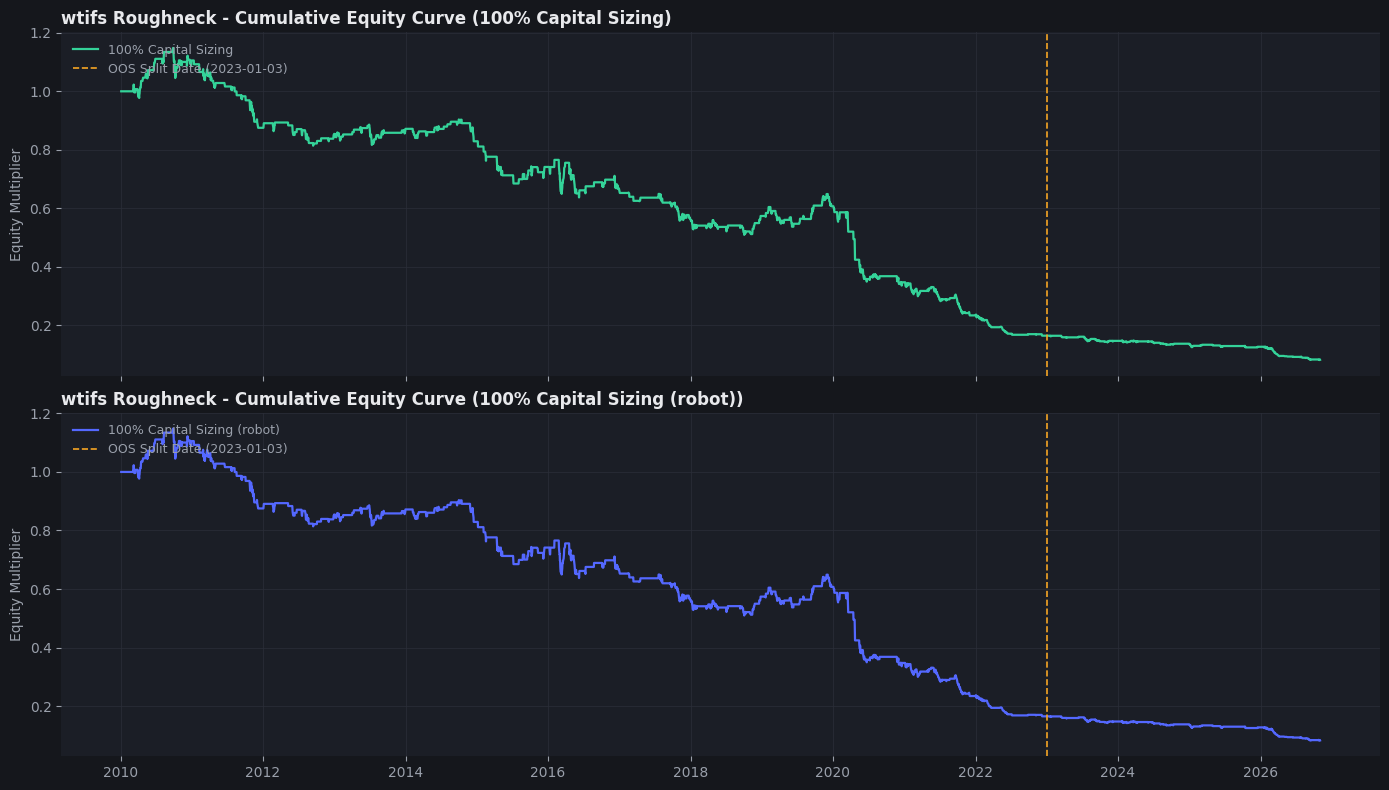

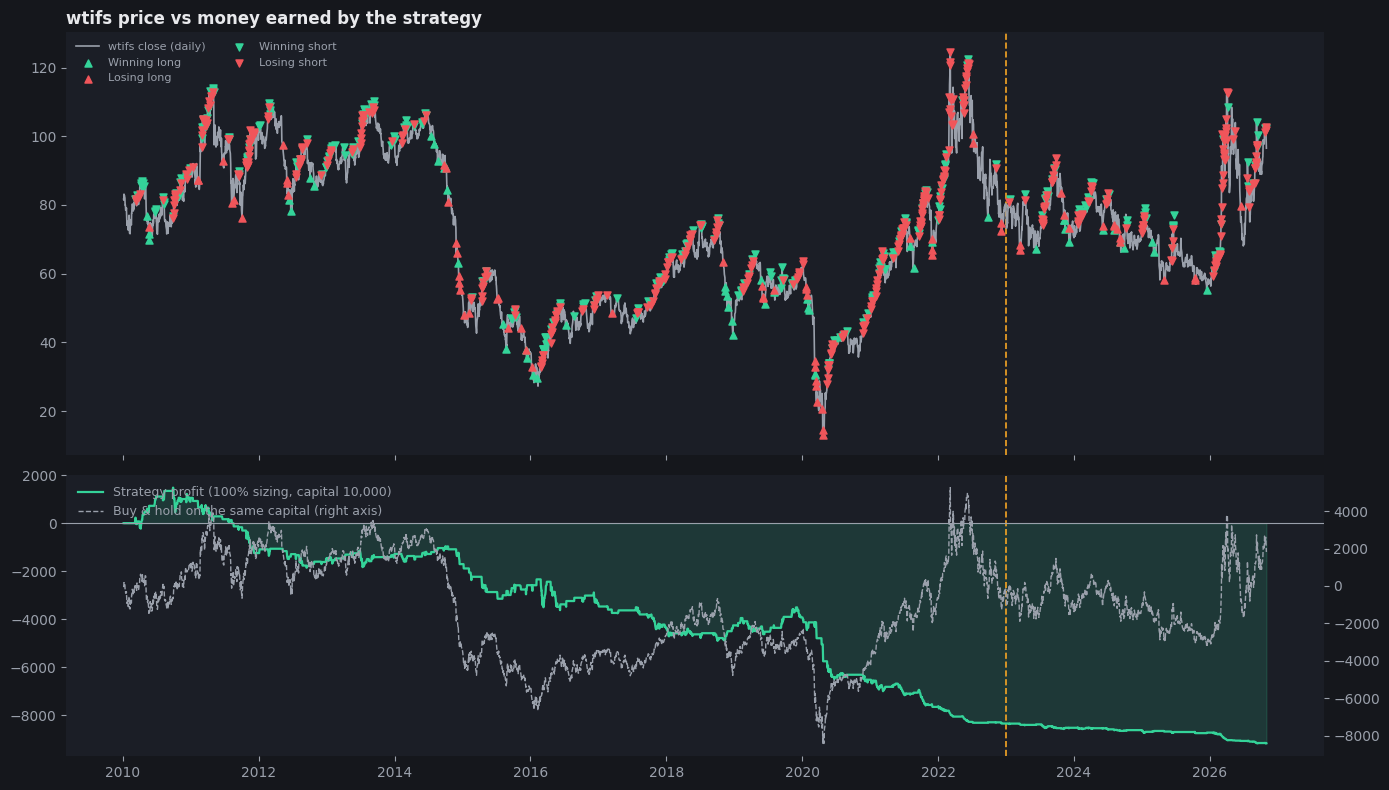

wtifs price change: +18% | strategy profit: -9,172 (-91.7% of 10,000) | buy & hold profit: 1,815 | time in market: 25.8%

CHECKS (5):
   [FAIL] Profit Factor, full period >= 1.3  ->  PF = 0.663
   [FAIL] Profit Factor, IS >= 1.3  ->  PF = 0.693
   [FAIL] Profit Factor, OOS >= 1.3  ->  PF = 0.550
   [PASS] OOS does not degrade vs IS (OOS PF >= 50% of IS PF)  ->  OOS 0.550 vs IS 0.693
   [FAIL] t-stat of the mean trade >= 2  ->  t = -5.40
   [PASS] Trades, full period >= 60  ->  802 trades
   [PASS] Trades, OOS >= 20  ->  181 trades
   [FAIL] Expectancy > 0 in IS and OOS (net of costs)  ->  IS -0.276% | OOS -0.373%


'FAIL'

In [9]:
trades_is  = eng.run_roughneck_backtest(df_is,  **RULES)
trades_oos = eng.run_roughneck_backtest(df_oos, **RULES)
trades_all = eng.run_roughneck_backtest(df,     **RULES)

def sized(t, sizing):
    return t if sizing == "capital" else t.assign(pnl=t["pnl_frac"], win=t["pnl_frac"] > 0)

def perf_row(t, price_df, period, sizing):
    m = compute_metrics(sized(t, sizing), contract_multiplier=1.0, cost_per_trade=0.0)
    ret = eng.daily_returns(price_df, t, sizing=sizing)
    eq = (1.0 + ret).cumprod()
    yrs = (price_df.index[-1] - price_df.index[0]).days / 365.25
    return {"Period": period, "Sizing": "100% Capital" if sizing == "capital" else f"{SIZE_FRAC:.0%} Capital (robot)",
            "Trades": m["num_trades"], "Win Rate": f"{m['win_rate']:.1f}%", "Profit Factor": f"{m['profit_factor']:.3f}",
            "Expectancy": f"{m['expectancy']:.3f}%", "Total Return": f"{(eq.iloc[-1] - 1) * 100:.1f}%",
            "CAGR": f"{((eq.iloc[-1] ** (1 / yrs)) - 1) * 100:.1f}%" if yrs > 0 else "n/a",
            "Sharpe": f"{sharpe_ratio(ret, periods_per_year=PPY):.2f}", "Max Drawdown": f"{max_drawdown(eq) * 100:.2f}%"}

periods = [(f"In-Sample ({df_is.index[0].year}-{df_is.index[-1].year})", trades_is, df_is),
           (f"Out-of-Sample ({df_oos.index[0].year}-{df_oos.index[-1].year})", trades_oos, df_oos),
           (f"Full Period ({df.index[0].year}-{df.index[-1].year})", trades_all, df)]
perf_table = pd.DataFrame([perf_row(t, d, name, s) for name, t, d in periods for s in ("capital", "fraction")])
print("=" * 80)
print(f"PERFORMANCE SUMMARY (NET OF {COST_BPS:g} BPS PER SIDE + SWAP · daily MTM drawdown, Sharpe annualised x{PPY})")
print("=" * 80)
display(perf_table)

ret_cap = eng.daily_returns(df, trades_all, sizing="capital")
ret_fr = eng.daily_returns(df, trades_all, sizing="fraction")
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True, facecolor=BG)
for ax, r, col, lab in ((ax1, ret_cap, GREEN, "100% Capital Sizing"), (ax2, ret_fr, "#5468ff", f"{SIZE_FRAC:.0%} Capital Sizing (robot)")):
    dark_ax(ax)
    ax.plot(r.index, (1 + r).cumprod(), color=col, lw=1.6, label=lab)
    ax.axvline(oos_start, color=ORANGE, ls="--", lw=1.2, label=f"OOS Split Date ({oos_start:%Y-%m-%d})")
    ax.set_title(f"{TICKER} Roughneck - Cumulative Equity Curve ({lab})", color=TXT, fontweight="bold", loc="left")
    ax.set_ylabel("Equity Multiplier", color=SUB)
    ax.legend(frameon=False, labelcolor=SUB, fontsize=9, loc="upper left")
plt.tight_layout(); plt.show()

profit_usd = CAPITAL * ((1.0 + ret_fr).cumprod() - 1.0)
buy_hold = CAPITAL * (df["close"] / df["close"].iloc[0] - 1.0)
entries = trades_all.assign(entry_time=pd.to_datetime(trades_all["entry_time"])).set_index("entry_time")
won = entries["pnl"] > 0
fig, (ax_px, ax_pl) = plt.subplots(2, 1, figsize=(14, 8), sharex=True, facecolor=BG, gridspec_kw={"height_ratios": [3, 2]})
for ax in (ax_px, ax_pl):
    dark_ax(ax); ax.grid(False); ax.axvline(oos_start, color=ORANGE, ls="--", lw=1.2)
ax_px.plot(df.index, df["close"], color=SUB, lw=1.2, label=f"{TICKER} close (daily)")
for sd, mk_up in (("long", "^"), ("short", "v")):
    e = entries[entries["type"] == sd]
    ax_px.scatter(e.index[e["pnl"] > 0], e.loc[e["pnl"] > 0, "entry_price"], marker=mk_up, s=26, color=GREEN, zorder=3, label=f"Winning {sd}")
    ax_px.scatter(e.index[e["pnl"] <= 0], e.loc[e["pnl"] <= 0, "entry_price"], marker=mk_up, s=26, color=RED, zorder=3, label=f"Losing {sd}")
ax_px.set_title(f"{TICKER} price vs money earned by the strategy", color=TXT, fontweight="bold", loc="left")
ax_px.legend(frameon=False, labelcolor=SUB, fontsize=8, loc="upper left", ncol=2)
ax_pl.plot(profit_usd.index, profit_usd, color=GREEN, lw=1.6, label=f"Strategy profit ({SIZE_FRAC:.0%} sizing, capital {CAPITAL:,.0f})")
ax_pl.fill_between(profit_usd.index, profit_usd, 0, color=GREEN, alpha=0.15)
ax_pl.axhline(0, color=SUB, lw=0.8)
ax_bh = ax_pl.twinx()
ax_bh.plot(buy_hold.index, buy_hold, color=SUB, lw=1.0, ls="--", label="Buy & hold on the same capital (right axis)")
ax_bh.grid(False); ax_bh.tick_params(colors=SUB)
for spine in ax_bh.spines.values():
    spine.set_visible(False)
h1, l1 = ax_pl.get_legend_handles_labels(); h2, l2 = ax_bh.get_legend_handles_labels()
ax_pl.legend(h1 + h2, l1 + l2, frameon=False, labelcolor=SUB, fontsize=9, loc="upper left")
plt.tight_layout(); plt.show()
in_market = float(trades_all["bars"].sum()) / len(df)
print(f"{TICKER} price change: {(df['close'].iloc[-1] / df['close'].iloc[0] - 1) * 100:+,.0f}% | strategy profit: {profit_usd.iloc[-1]:,.0f} "
      f"({profit_usd.iloc[-1] / CAPITAL * 100:+.1f}% of {CAPITAL:,.0f}) | buy & hold profit: {buy_hold.iloc[-1]:,.0f} | time in market: {in_market * 100:.1f}%")

print("\nCHECKS (5):")
m_is, m_oos, m_all = (compute_metrics(t, 1.0, 0.0) for t in (trades_is, trades_oos, trades_all))
t_all = tstat(trades_all["pnl"])
check("5. Baseline", f"Profit Factor, full period >= {PF_MIN:g}", m_all["profit_factor"] >= PF_MIN, f"PF = {m_all['profit_factor']:.3f}")
check("5. Baseline", f"Profit Factor, IS >= {PF_MIN:g}", m_is["profit_factor"] >= PF_MIN, f"PF = {m_is['profit_factor']:.3f}")
check("5. Baseline", f"Profit Factor, OOS >= {PF_MIN:g}", m_oos["profit_factor"] >= PF_MIN, f"PF = {m_oos['profit_factor']:.3f}")
check("5. Baseline", "OOS does not degrade vs IS (OOS PF >= 50% of IS PF)", m_oos["profit_factor"] >= 0.5 * m_is["profit_factor"], f"OOS {m_oos['profit_factor']:.3f} vs IS {m_is['profit_factor']:.3f}")
check("5. Baseline", f"t-stat of the mean trade >= {T_MIN:g}", t_all >= T_MIN, f"t = {t_all:.2f}")
check("5. Baseline", f"Trades, full period >= {N_MIN}", m_all["num_trades"] >= N_MIN, f"{m_all['num_trades']} trades")
check("5. Baseline", f"Trades, OOS >= {N_OOS_MIN}", m_oos["num_trades"] >= N_OOS_MIN, f"{m_oos['num_trades']} trades")
check("5. Baseline", "Expectancy > 0 in IS and OOS (net of costs)", m_is["expectancy"] > 0 and m_oos["expectancy"] > 0, f"IS {m_is['expectancy']:+.3f}% | OOS {m_oos['expectancy']:+.3f}%")

## 5.1 LOT-ADJUSTED SIZING AND HARD LIMIT (CFD)
Daily bars: the drawdown is measured on daily closes and, more strictly, **intrabar** (candle extremes, gap exits included), which is what a broker kill-switch sees.

HARD LIMIT -9% · LOT-ADJUSTED SIZING (min lot 0.01, step 0.01, 1000 bbl per lot)


,Sizing,Trades taken,Total Return,Max DD (daily MTM),Max DD (intrabar),Headroom (intrabar),Hard limit
0,100% ideal fraction,802,-91.7%,-92.86%,-93.19%,-84.19 pts,FAIL
1,"Lot-adjusted (capital 10,000)",802,-90.9%,-92.07%,-92.44%,-83.44 pts,FAIL


Minimum capital so the minimum lot weighs <= 100% at 96.52: 965
Minimum capital so the minimum lot survives the worst historical adverse move ($18.72/bbl) inside -9%: 2,080
Largest fixed fraction that keeps the intrabar drawdown inside -9%: 3.6% (configured: 100%)

CHECKS (5.1):
   [FAIL] 100% ideal fraction stays inside -9% (intrabar)  ->  max DD -93.19% | headroom -84.19 pts
   [FAIL] Lot-adjusted sizing stays inside -9% (intrabar)  ->  max DD -92.44% | headroom -83.44 pts
   [FAIL] Configured fraction <= largest fraction allowed by the limit  ->  100% vs 3.6%
   [PASS] Capital >= minimum capital for the minimum lot  ->  10,000 vs 965
   [PASS] Capital >= minimum capital for the worst historical gap  ->  10,000 vs 2,080
   [PASS] Every trade is executable with the minimum lot  ->  802 of 802 trades taken


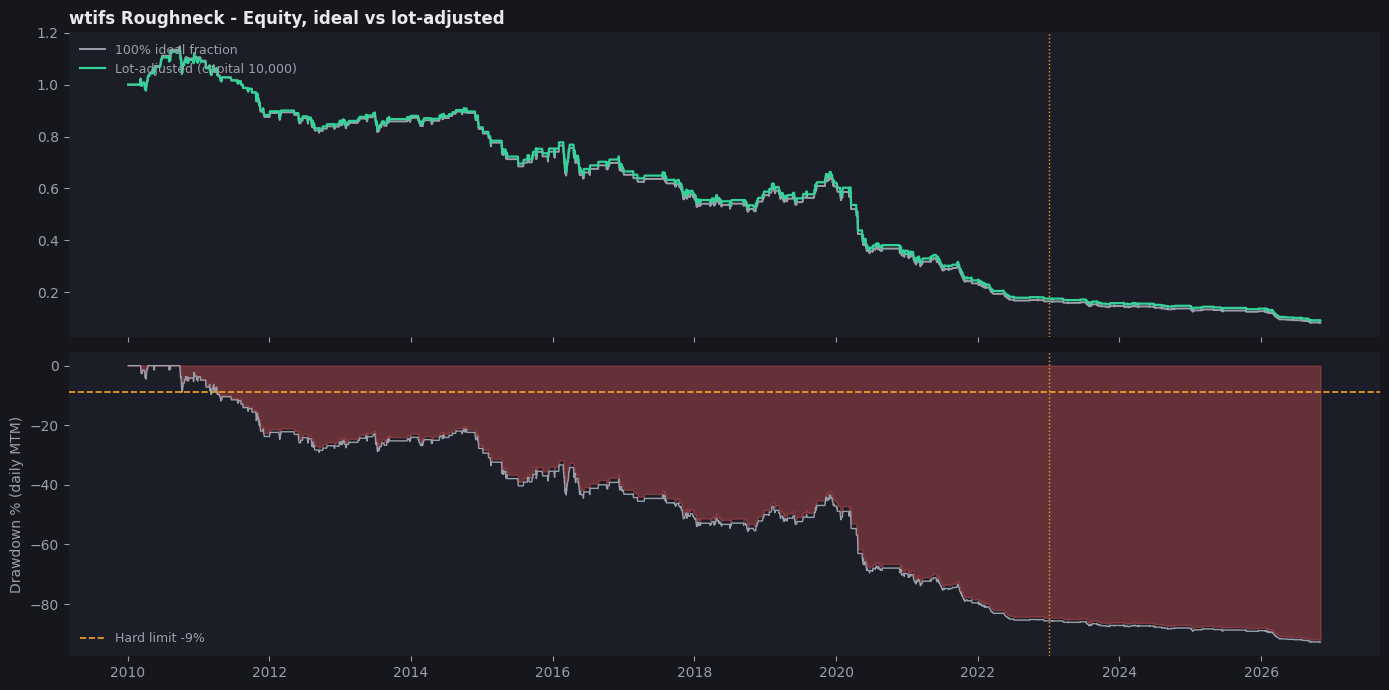

In [10]:
last_price = float(df["close"].iloc[-1])
min_capital = eng.min_capital_for_target(last_price, SIZE_FRAC)
max_frac = eng.max_fraction_for_limit(df, trades_all, HARD_LIMIT)
lot_sizes = eng.cfd_trade_sizes(trades_all, CAPITAL, SIZE_FRAC)
daily_ideal = eng.hourly_returns(df, trades_all, sizing="fraction")
daily_lot = eng.hourly_returns(df, trades_all, sizing=lot_sizes["size_fraction"].to_numpy())

def drawdown_series(r):
    eq = (1.0 + r).cumprod()
    return eq / np.maximum(eq.cummax(), 1.0) - 1.0

def limit_row(label, ret, sizing, n_taken):
    rep, rep_ib = eng.hard_limit_report(ret, HARD_LIMIT), eng.hard_limit_report_intrabar(df, trades_all, HARD_LIMIT, sizing)
    return {"Sizing": label, "Trades taken": n_taken, "Total Return": f"{((1.0 + ret).prod() - 1.0) * 100:.1f}%",
            "Max DD (daily MTM)": f"{rep['max_dd'] * 100:.2f}%", "Max DD (intrabar)": f"{rep_ib['max_dd'] * 100:.2f}%",
            "Headroom (intrabar)": f"{rep_ib['headroom'] * 100:+.2f} pts", "Hard limit": "PASS" if rep_ib["passed"] else "FAIL"}

limit_table = pd.DataFrame([limit_row(f"{SIZE_FRAC:.0%} ideal fraction", daily_ideal, "fraction", len(trades_all)),
                            limit_row(f"Lot-adjusted (capital {CAPITAL:,.0f})", daily_lot, lot_sizes["size_fraction"].to_numpy(), int(lot_sizes["taken"].sum()))])
print("=" * 80)
print(f"HARD LIMIT -{HARD_LIMIT:.0%} · LOT-ADJUSTED SIZING (min lot {MIN_LOT:g}, step {LOT_STEP:g}, {CONTRACT_SIZE:g} bbl per lot)")
print("=" * 80)
display(limit_table)
worst_move = eng.worst_adverse_move(df, trades_all)
min_cap_gap = MIN_LOT * CONTRACT_SIZE * worst_move / HARD_LIMIT
print(f"Minimum capital so the minimum lot weighs <= {SIZE_FRAC:.0%} at {last_price:,.2f}: {min_capital:,.0f}")
print(f"Minimum capital so the minimum lot survives the worst historical adverse move (${worst_move:.2f}/bbl) inside -{HARD_LIMIT:.0%}: {min_cap_gap:,.0f}")
print(f"Largest fixed fraction that keeps the intrabar drawdown inside -{HARD_LIMIT:.0%}: {max_frac:.1%} (configured: {SIZE_FRAC:.0%})")

print("\nCHECKS (5.1):")
rep_ideal = eng.hard_limit_report_intrabar(df, trades_all, HARD_LIMIT, "fraction")
rep_lot = eng.hard_limit_report_intrabar(df, trades_all, HARD_LIMIT, lot_sizes["size_fraction"].to_numpy())
check("5.1 Hard limit", f"{SIZE_FRAC:.0%} ideal fraction stays inside -{HARD_LIMIT:.0%} (intrabar)", rep_ideal["passed"], f"max DD {rep_ideal['max_dd'] * 100:.2f}% | headroom {rep_ideal['headroom'] * 100:+.2f} pts")
check("5.1 Hard limit", f"Lot-adjusted sizing stays inside -{HARD_LIMIT:.0%} (intrabar)", rep_lot["passed"], f"max DD {rep_lot['max_dd'] * 100:.2f}% | headroom {rep_lot['headroom'] * 100:+.2f} pts")
check("5.1 Hard limit", "Configured fraction <= largest fraction allowed by the limit", SIZE_FRAC <= max_frac, f"{SIZE_FRAC:.0%} vs {max_frac:.1%}")
check("5.1 Hard limit", "Capital >= minimum capital for the minimum lot", CAPITAL >= min_capital, f"{CAPITAL:,.0f} vs {min_capital:,.0f}")
check("5.1 Hard limit", "Capital >= minimum capital for the worst historical gap", CAPITAL >= min_cap_gap, f"{CAPITAL:,.0f} vs {min_cap_gap:,.0f}")
check("5.1 Hard limit", "Every trade is executable with the minimum lot", int(lot_sizes["taken"].sum()) == len(trades_all), f"{int(lot_sizes['taken'].sum())} of {len(trades_all)} trades taken")

dd_ideal, dd_lot = drawdown_series(daily_ideal), drawdown_series(daily_lot)
fig, (ax_eq, ax_dd) = plt.subplots(2, 1, figsize=(14, 7), sharex=True, facecolor=BG)
for ax in (ax_eq, ax_dd):
    dark_ax(ax); ax.grid(False); ax.axvline(oos_start, color=ORANGE, ls=":", lw=1.0)
ax_eq.plot(daily_ideal.index, (1.0 + daily_ideal).cumprod(), color=SUB, lw=1.4, label=f"{SIZE_FRAC:.0%} ideal fraction")
ax_eq.plot(daily_lot.index, (1.0 + daily_lot).cumprod(), color=GREEN, lw=1.6, label=f"Lot-adjusted (capital {CAPITAL:,.0f})")
ax_eq.set_title(f"{TICKER} Roughneck - Equity, ideal vs lot-adjusted", color=TXT, fontweight="bold", loc="left")
ax_eq.legend(frameon=False, labelcolor=SUB, fontsize=9, loc="upper left")
ax_dd.plot(dd_ideal.index, dd_ideal * 100, color=SUB, lw=1.0)
ax_dd.fill_between(dd_lot.index, dd_lot * 100, 0, color=RED, alpha=0.35)
ax_dd.axhline(-HARD_LIMIT * 100, color=ORANGE, ls="--", lw=1.2, label=f"Hard limit -{HARD_LIMIT:.0%}")
ax_dd.set_ylabel("Drawdown % (daily MTM)", color=SUB)
ax_dd.legend(frameon=False, labelcolor=SUB, fontsize=9, loc="lower left")
plt.tight_layout(); plt.show()

## 5.2 ANNUAL RETURNS AND HARD LIMIT CHECK

ANNUAL RETURNS · LOT-ADJUSTED · HARD LIMIT -9% · * = partial year


,year,ret,mdd,breach,partial
0,2010,+10.0%,-8.7%,False,False
1,2011,-19.8%,-19.8%,True,False
2,2012,-2.4%,-8.6%,False,False
3,2013,+2.1%,-7.5%,False,False
4,2014,-5.0%,-8.1%,False,False
5,2015,-9.8%,-16.7%,True,False
6,2016,-9.9%,-16.3%,True,False
7,2017,-15.0%,-15.7%,True,False
8,2018,+1.8%,-9.3%,True,False
9,2019,+5.9%,-10.8%,True,False


Steps below the limit: 4016 | first breach: 2011-03-09 00:00:00

CHECKS (5.2):
   [FAIL] No calendar year breaches the hard limit  ->  years in breach: [2011, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2026] | worst year DD -43.9%
   [FAIL] >= 60% of full calendar years are profitable  ->  4/16 full years positive | non-positive: 2011 (-19.8%), 2012 (-2.4%), 2014 (-5.0%), 2015 (-9.8%), 2016 (-9.9%), 2017 (-15.0%), 2020 (-42.1%), 2021 (-31.7%), 2022 (-28.5%), 2023 (-10.1%), 2024 (-6.3%), 2025 (-7.4%)


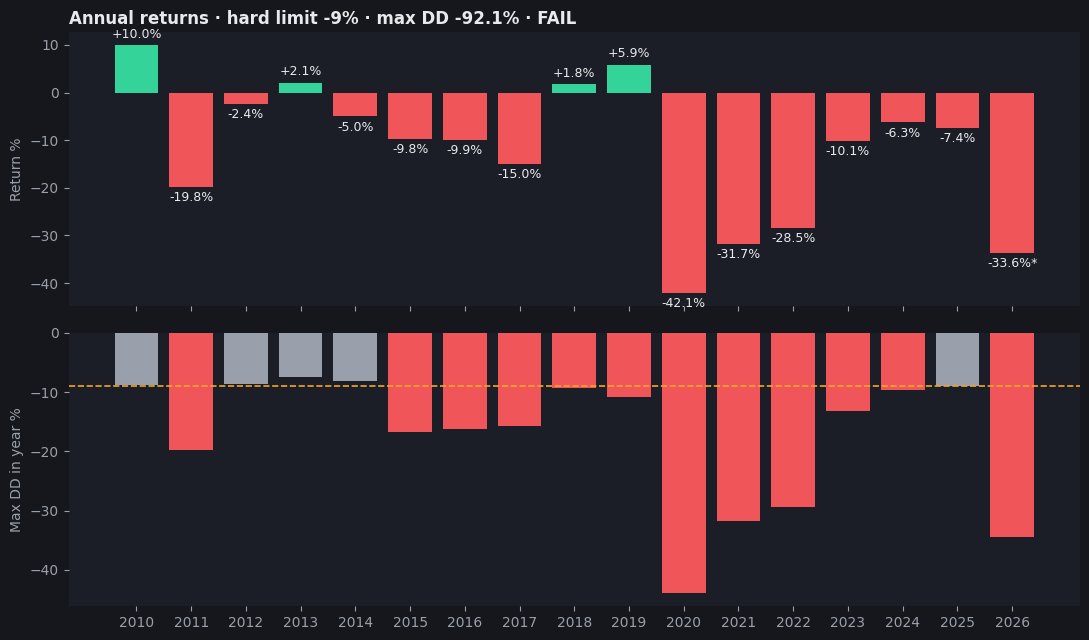

In [11]:
def plot_annual_returns(annual, report, hard_limit):
    fig, (ax_ret, ax_dd) = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True, facecolor=BG)
    years = annual["year"].astype(str).to_numpy()
    bars = ax_ret.bar(years, annual["ret"] * 100, color=[GREEN if v >= 0 else RED for v in annual["ret"]])
    ax_dd.bar(years, annual["mdd"] * 100, color=[RED if b else SUB for b in annual["breach"]])
    ax_dd.axhline(-hard_limit * 100, color=ORANGE, ls="--", lw=1.2)
    for ax in (ax_ret, ax_dd):
        dark_ax(ax); ax.grid(False)
    for rect, value, partial in zip(bars, annual["ret"], annual["partial"]):
        ax_ret.annotate(f"{value:+.1%}" + ("*" if partial else ""), (rect.get_x() + rect.get_width() / 2, value * 100),
                        xytext=(0, 3 if value >= 0 else -3), textcoords="offset points", ha="center",
                        va="bottom" if value >= 0 else "top", color=TXT, fontsize=9)
    ax_ret.set_title(f"Annual returns · hard limit -{hard_limit:.0%} · max DD {report['max_dd']:.1%} · {'PASS' if report['passed'] else 'FAIL'}", color=TXT, fontweight="bold", loc="left")
    ax_ret.set_ylabel("Return %", color=SUB); ax_dd.set_ylabel("Max DD in year %", color=SUB)
    plt.tight_layout(); plt.show()

annual = eng.annual_returns(daily_lot, trades_all, HARD_LIMIT)
report_annual = eng.hard_limit_report(daily_lot, HARD_LIMIT)
print("=" * 80)
print(f"ANNUAL RETURNS · LOT-ADJUSTED · HARD LIMIT -{HARD_LIMIT:.0%} · * = partial year")
print("=" * 80)
display(annual.style.format({"ret": "{:+.1%}", "mdd": "{:.1%}"}))
print(f"Steps below the limit: {report_annual['steps_in_breach']} | first breach: {report_annual['first_breach']}")

print("\nCHECKS (5.2):")
full_y = annual[~annual["partial"]]
neg = full_y[full_y["ret"] <= 0]
n_pos = len(full_y) - len(neg)
breach_years = annual.loc[annual["breach"], "year"].astype(int).tolist()
check("5.2 Annual", "No calendar year breaches the hard limit", not annual["breach"].any(), f"years in breach: {breach_years if breach_years else 'none'} | worst year DD {annual['mdd'].min() * 100:.1f}%")
check("5.2 Annual", f">= {YEARS_POS_MIN:.0%} of full calendar years are profitable", len(full_y) > 0 and n_pos / len(full_y) >= YEARS_POS_MIN,
      f"{n_pos}/{len(full_y)} full years positive" + (" | non-positive: " + ", ".join(f"{int(y)} ({r:+.1%})" for y, r in zip(neg["year"], neg["ret"])) if len(neg) else ""))
plot_annual_returns(annual, report_annual, HARD_LIMIT)

## 6. SANITY CHECKS & VERIFICATION

In [12]:
print("=" * 70)
print("SANITY CHECKS & REPRODUCIBILITY")
print("=" * 70)

# 1. No lookahead + execution model (violations are collected, not asserted, so the notebook keeps running)
violations, prev_end = [], None
for idx_, r in trades_all.iterrows():
    et, xt = pd.Timestamp(r["entry_time"]), pd.Timestamp(r["exit_time"])
    i_e, i_s, sd = int(r["i_ent"]), int(r["i_sal"]), (1 if r["type"] == "long" else -1)
    sig = df.iloc[i_e - 1]
    if not (df.index[i_e] == et and df.index[i_s] == xt):
        violations.append(f"trade {idx_}: i_ent / i_sal misaligned")
    if not ((sig["long_sig"] and sd == 1) or (sig["short_sig"] and sd == -1)):
        violations.append(f"trade {idx_}: no signal on the previous close")
    stop_px = sig["long_stop_px"] if sd == 1 else sig["short_stop_px"]
    bar = df.iloc[i_e]
    if sd == 1 and not (bar["high"] >= stop_px and np.isclose(r["entry_price"], max(stop_px, bar["open"]))):
        violations.append(f"trade {idx_}: long entry is not max(stop, open)")
    if sd == -1 and not (bar["low"] <= stop_px and np.isclose(r["entry_price"], min(stop_px, bar["open"]))):
        violations.append(f"trade {idx_}: short entry is not min(stop, open)")
    if not (df["low"].iloc[i_e:i_s + 1].min() - 1e-9 <= r["exit_price"] <= df["high"].iloc[i_e:i_s + 1].max() + 1e-9) and r["exit_reason"] != "end_of_data":
        violations.append(f"trade {idx_}: exit price outside the candle range")
    if r["exit_reason"] in ("stop", "gap_stop", "stop_entry_bar") and sd * (r["exit_price"] - r["entry_price"]) < -RULES["stop_dollar"] - 1e-9 and r["exit_reason"] != "gap_stop":
        violations.append(f"trade {idx_}: loss beyond the base stop without a gap")
    if prev_end is not None and i_e < prev_end:
        violations.append(f"trade {idx_}: overlaps the previous trade")
    prev_end = i_s
print(f"Sanity Check 1: signal on the previous close, buy/sell stop fill = max/min(stop, open), exit inside the candle, loss <= base stop unless gap, no overlap ({len(trades_all)} trades).")
check("6. Sanity", "No lookahead and execution model respected on every trade", not violations,
      f"{len(trades_all)} trades checked" + (f" | {len(violations)} violations, first: {violations[0]}" if violations else ""))

# 2. Trade distribution per calendar year (full years only)
trades_all["year"] = pd.to_datetime(trades_all["entry_time"]).dt.year
tpy = trades_all.groupby("year").size()
full_years = [y for y in range(df.index[0].year, df.index[-1].year + 1) if pd.Timestamp(f"{y}-01-07") >= df.index[0] and pd.Timestamp(f"{y}-12-24") <= df.index[-1]]
tpy_full = tpy.reindex(full_years, fill_value=0)
print("\nSanity Check 2: Trade Frequency per Year:")
print(f"   - Average trades per year: {tpy.mean():.1f} (published modern period: ~{REF_TRADES_PER_YEAR})")
print(f"   - Min trades (full years): {tpy_full.min()} ({tpy_full.idxmin()}) | Max trades: {tpy.max()} ({tpy.idxmax()})")
check("6. Sanity", f"Every full calendar year has >= {MIN_TRADES_PER_YEAR} trades", (tpy_full >= MIN_TRADES_PER_YEAR).all(), f"min {tpy_full.min()} ({tpy_full.idxmin()}) | max {tpy_full.max()} over {len(tpy_full)} full years")

# 3. MTM paths reproduce the trade returns exactly
paths = eng.trade_mtm_paths(df, trades_all, sizing="capital")
err = max(abs(np.prod(1 + p) - (1 + pnl / 100)) for p, pnl in zip(paths, trades_all["pnl"]))
print(f"\nSanity Check 3: MTM paths telescope to trade returns (max abs error {err:.2e}).")
check("6. Sanity", "MTM paths telescope to the trade returns (error < 1e-9)", err < 1e-9, f"max abs error {err:.2e}")

# 4. Indicators on the FULL history = indicators on a truncated history (the signal never uses the future)
cut = len(df) - 250
tr_cut = eng.run_roughneck_backtest(prep(df_raw.iloc[:cut]), **RULES)
a_ = trades_all[trades_all["i_sal"] < cut - 5][["entry_time", "exit_time", "entry_price", "exit_price"]].reset_index(drop=True)
b_ = tr_cut[tr_cut["i_sal"] < cut - 5][["entry_time", "exit_time", "entry_price", "exit_price"]].reset_index(drop=True)
check("6. Sanity", "No lookahead: truncating the last year does not change earlier trades", a_.equals(b_), f"{len(a_)} trades compared")

# 5. Placebo: on pure random walks (intraday-consistent candles, zero cost AND zero swap) the engine must find NO edge (PF ~ 1)
def _random_walk(seed, n=2500):
    rng = np.random.default_rng(seed)
    steps = rng.normal(0, 0.02 / np.sqrt(20), (n, 20))
    start = np.concatenate([[np.log(65)], np.log(65) + np.cumsum(steps.sum(1))[:-1]])
    pth = np.exp(start[:, None] + np.cumsum(steps, 1)); o = np.exp(start)
    return pd.DataFrame({"open": o, "high": np.maximum(pth.max(1), o), "low": np.minimum(pth.min(1), o), "close": pth[:, -1]}, index=pd.bdate_range("2016-01-04", periods=n))
plc = []
_fin_saved = eng.ENGINE_DEFAULTS["financing_bps_per_night"]
eng.set_engine_defaults(financing_bps_per_night=0.0)      # swap would bias the placebo below 1
try:
    for sd_ in range(20):
        tp = eng.run_roughneck_backtest(prep(_random_walk(sd_)), **{**RULES, "cost_bps_per_side": 0.0})
        plc.append(tp.loc[tp.pnl > 0, "pnl"].sum() / max(-tp.loc[tp.pnl < 0, "pnl"].sum(), 1e-9))
finally:
    eng.set_engine_defaults(financing_bps_per_night=_fin_saved)
print(f"\nSanity Check 5: placebo on 20 random walks, zero cost, zero swap: mean PF {np.mean(plc):.3f} (an unbiased engine gives ~1.0)")
check("6. Sanity", "Placebo: no edge on random walks (mean PF within 0.85-1.15)", 0.85 <= np.mean(plc) <= 1.15, f"mean PF {np.mean(plc):.3f}")

# 6. Cross-check with the published reference (other instrument and period: informational, wide tolerance)
print("\nSanity Check 6: comparison with the published reference (TradeStation back-adjusted CL; cost model not stated; informational):")
check("6. Sanity", "Trades per year within 0.4x-2.5x of the published ~9.8", 0.4 * REF_TRADES_PER_YEAR <= tpy.mean() <= 2.5 * REF_TRADES_PER_YEAR,
      f"ours {tpy.mean():.1f} vs published {REF_TRADES_PER_YEAR}")
check("6. Sanity", "Win rate within 15 points of the published 74%", abs(m_all["win_rate"] - REF_WIN) <= 15, f"ours {m_all['win_rate']:.1f}% vs published {REF_WIN}%")
check("6. Sanity", "PF at least 50% of the published 1.81 (different instrument, period and cost model)", m_all["profit_factor"] >= 0.5 * REF_PF, f"ours {m_all['profit_factor']:.3f} vs published {REF_PF}")

SANITY CHECKS & REPRODUCIBILITY
Sanity Check 1: signal on the previous close, buy/sell stop fill = max/min(stop, open), exit inside the candle, loss <= base stop unless gap, no overlap (802 trades).
   [FAIL] No lookahead and execution model respected on every trade  ->  802 trades checked | 1603 violations, first: trade 0: no signal on the previous close

Sanity Check 2: Trade Frequency per Year:
   - Average trades per year: 47.2 (published modern period: ~9.8)
   - Min trades (full years): 26 (2017) | Max trades: 90 (2021)
   [PASS] Every full calendar year has >= 3 trades  ->  min 26 (2017) | max 90 over 16 full years

Sanity Check 3: MTM paths telescope to trade returns (max abs error 2.22e-16).
   [PASS] MTM paths telescope to the trade returns (error < 1e-9)  ->  max abs error 2.22e-16
   [PASS] No lookahead: truncating the last year does not change earlier trades  ->  731 trades compared

Sanity Check 5: placebo on 20 random walks, zero cost, zero swap: mean PF 0.825 (an unbias

'FAIL'

## 7. REFERENCE VARIANTS (SAME BARS, SAME COSTS, SAME SIZE) · THE NEWSLETTER'S OPEN QUESTIONS
Naked trigger vs no-ATR-tiers vs long-only vs configured, plus ATR as a simple average vs Wilder, and a doubled cost (the newsletter asks whether $200 or $100 round trip changes the picture).

VARIANT COMPARISON (100% capital per trade, 4 bps/side)


,Variant,Trades,Win Rate,Profit Factor,Sharpe,Max Drawdown,Final Capital
0,Naked trigger (no trend),1683,43.9%,0.671,-1.79,-99.55%,0.00x
1,No ATR tiers,802,43.1%,0.663,-1.28,-92.86%,0.08x
2,Long only,118,43.2%,0.636,-0.51,-41.82%,0.60x
3,ATR Wilder,807,42.5%,0.638,-1.41,-94.41%,0.06x
4,Costs x2,802,43.1%,0.593,-1.62,-96.17%,0.04x
5,Configured,802,43.1%,0.663,-1.28,-92.86%,0.08x



CHECKS (7):
   [FAIL] Configured Profit Factor beats naked trigger and no-tiers variant  ->  configured 0.663 | naked 0.671 | no-tiers 0.663
   [FAIL] Configured Sharpe beats naked trigger and no-tiers variant  ->  configured -1.28 | naked -1.79 | no-tiers -1.28
   [FAIL] Configured max drawdown is shallower than naked trigger and no-tiers variant  ->  configured -92.86% | naked -99.55% | no-tiers -92.86%
   [FAIL] Edge survives doubled costs (PF >= 1.1)  ->  PF 0.593
   [PASS] ATR method does not change the verdict (Wilder PF >= 80% of simple-ATR PF)  ->  Wilder 0.638 vs simple 0.663


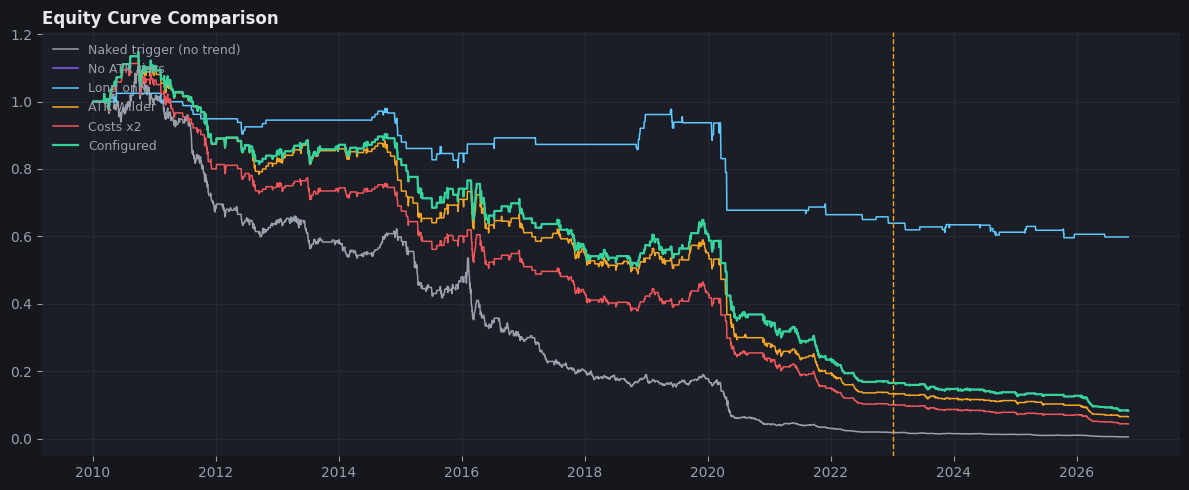

In [13]:
df_wil = prep(df_raw, atr_method="wilder")
variants = {"Naked trigger (no trend)": tr_naked,
            "No ATR tiers": tr_ex["No ATR tiers"],
            "Long only": eng.run_roughneck_backtest(df, **{**RULES, "side": "long"}),
            "ATR Wilder": eng.run_roughneck_backtest(df_wil, **{**RULES, "atr_method": "wilder"}),
            "Costs x2": eng.run_roughneck_backtest(df, **{**RULES, "cost_bps_per_side": 2 * COST_BPS}),
            "Configured": trades_all}
rows, curves, raw = [], {}, {}
for name, t in variants.items():
    mt = compute_metrics(t, 1.0, 0.0)
    r = eng.daily_returns(df, t, sizing="fraction")
    eq = (1 + r).cumprod()
    curves[name] = eq
    raw[name] = {"pf": mt["profit_factor"], "exp": mt["expectancy"], "sharpe": sharpe_ratio(r, periods_per_year=PPY), "mdd": max_drawdown(eq), "final": float(eq.iloc[-1])}
    rows.append({"Variant": name, "Trades": mt["num_trades"], "Win Rate": f"{mt['win_rate']:.1f}%", "Profit Factor": f"{mt['profit_factor']:.3f}",
                 "Sharpe": f"{raw[name]['sharpe']:.2f}", "Max Drawdown": f"{raw[name]['mdd'] * 100:.2f}%", "Final Capital": f"{eq.iloc[-1]:.2f}x"})
print("=" * 80)
print(f"VARIANT COMPARISON ({SIZE_FRAC:.0%} capital per trade, {COST_BPS:g} bps/side)")
print("=" * 80)
display(pd.DataFrame(rows))

print("\nCHECKS (7):")
cf = raw["Configured"]
check("7. Variants", "Configured Profit Factor beats naked trigger and no-tiers variant", all(cf["pf"] > raw[k]["pf"] for k in ("Naked trigger (no trend)", "No ATR tiers")),
      f"configured {cf['pf']:.3f} | naked {raw['Naked trigger (no trend)']['pf']:.3f} | no-tiers {raw['No ATR tiers']['pf']:.3f}")
check("7. Variants", "Configured Sharpe beats naked trigger and no-tiers variant", all(cf["sharpe"] > raw[k]["sharpe"] for k in ("Naked trigger (no trend)", "No ATR tiers")),
      f"configured {cf['sharpe']:.2f} | naked {raw['Naked trigger (no trend)']['sharpe']:.2f} | no-tiers {raw['No ATR tiers']['sharpe']:.2f}")
check("7. Variants", "Configured max drawdown is shallower than naked trigger and no-tiers variant", all(cf["mdd"] > raw[k]["mdd"] for k in ("Naked trigger (no trend)", "No ATR tiers")),
      f"configured {cf['mdd'] * 100:.2f}% | naked {raw['Naked trigger (no trend)']['mdd'] * 100:.2f}% | no-tiers {raw['No ATR tiers']['mdd'] * 100:.2f}%")
check("7. Variants", "Edge survives doubled costs (PF >= 1.1)", raw["Costs x2"]["pf"] >= 1.1, f"PF {raw['Costs x2']['pf']:.3f}")
check("7. Variants", "ATR method does not change the verdict (Wilder PF >= 80% of simple-ATR PF)", raw["ATR Wilder"]["pf"] >= 0.8 * cf["pf"], f"Wilder {raw['ATR Wilder']['pf']:.3f} vs simple {cf['pf']:.3f}")

fig, ax = plt.subplots(figsize=(12, 5), facecolor=BG)
dark_ax(ax)
for (name, eq), col in zip(curves.items(), (SUB, "#8a5cf5", "#5ec8ff", ORANGE, RED, GREEN)):
    ax.plot(eq.index, eq, color=col, lw=1.6 if name == "Configured" else 1.1, label=name)
ax.axvline(oos_start, color=ORANGE, ls="--", lw=1.0)
ax.set_title("Equity Curve Comparison", color=TXT, fontweight="bold", loc="left")
ax.legend(frameon=False, labelcolor=SUB, fontsize=9, loc="upper left")
plt.tight_layout(); plt.show()

## 8. SUMMARY OF HYPOTHESIS & NEXT STEPS

In [14]:
m_all, m_is, m_oos = (compute_metrics(t, 1.0, 0.0) for t in (trades_all, trades_is, trades_oos))
t_all = tstat(trades_all["pnl"])
max_dd_fr = max_drawdown((1 + eng.daily_returns(df, trades_all, sizing="fraction")).cumprod()) * 100
years = (df.index[-1] - df.index[0]).days / 365.25
next_nb = "02_Roughneck_Optimization.ipynb"

confirmed = bool(m_all["profit_factor"] >= PF_MIN and m_oos["profit_factor"] >= PF_MIN and t_all >= T_MIN and m_all["num_trades"] >= N_MIN)
verdict = "Hypothesis Confirmed" if confirmed else "Hypothesis NOT clearly confirmed"
check("8. Verdict", f"Core criteria: PF >= {PF_MIN:g} (full and OOS), t >= {T_MIN:g}, N >= {N_MIN}", confirmed,
      f"PF {m_all['profit_factor']:.3f} / OOS {m_oos['profit_factor']:.3f} | t {t_all:.2f} | N {m_all['num_trades']}", quiet=True)

# ---- GO / STOP gate: only the checks that decide whether the research continues ----
ESSENTIAL = [
    ("3. Data",         "Prices are strictly positive",       "Fix the data first (rollover / negative-price handling): every other number is invalid until this passes."),
    ("3. Data",         "Close-to-open jumps",                "Rollover jumps contaminate gaps and stops: use a cash CFD or a back-adjusted series."),
    ("6. Sanity",       "No lookahead",                       "Fix the execution model / lookahead first: every other number is invalid until this passes."),
    ("6. Sanity",       "Placebo",                            "The engine finds an edge on random walks: it has a bias (intrabar ordering or lookahead). Fix it first."),
    ("6. Sanity",       "No lookahead: truncating",           "The signal uses future data: fix prepare() before anything else."),
    ("5. Baseline",     "Profit Factor, IS",                  "Baseline does not hold in-sample: the hypothesis is not supported, rethink the rules before optimizing."),
    ("5. Baseline",     "Profit Factor, OOS",                 "Baseline does not hold out-of-sample: do not optimize, the edge is not confirmed."),
    ("5. Baseline",     "t-stat of the mean trade",           "The mean trade is not statistically significant: the edge could be noise."),
    ("5. Baseline",     "Trades, full period",                "Too few trades to conclude anything: more history is needed."),
    ("5. Baseline",     "Trades, OOS",                        "Too few OOS trades to validate the edge."),
    ("4.1 Trend filter", "Configured PF beats the naked",     "The trend filter does not add value over the naked trigger: revisit the filter."),
    ("4.4 Exits",       "The ATR trailing tiers add value",   "The ATR trailing tiers do not improve PF: the exit machinery is not justified."),
    ("7. Variants",     "Edge survives doubled costs",        "The edge does not survive 2x costs: the broker's spread and swap decide whether it exists."),
    ("5.1 Hard limit",  "Lot-adjusted sizing stays inside",   "Lot-adjusted sizing breaks the hard limit: reduce the size fraction or raise capital."),
    ("5.1 Hard limit",  "Capital >= minimum capital for the minimum lot", "Capital is below what the minimum lot needs."),
    ("5.1 Hard limit",  "Capital >= minimum capital for the worst", "The minimum lot cannot survive the worst historical gap inside the hard limit: raise capital or use a smaller contract."),
    ("5.2 Annual",      "No calendar year breaches",          "A calendar year breaches the hard limit: review sizing or the rules of that year."),
]
chk = pd.DataFrame(CHECKS)
n_pass, n_fail, n_skip = (int((chk["status"] == s).sum()) for s in ("PASS", "FAIL", "SKIP"))
key = {(s, n): a for s, n, a in ESSENTIAL}
chk["essential"] = [any(sec == s and nm.startswith(n) for s, n, _ in ESSENTIAL) for sec, nm in zip(chk["section"], chk["name"])]
ess = chk[chk["essential"]]
missing = [f"{s}: {n}" for s, n, _ in ESSENTIAL if not ((chk["section"] == s) & chk["name"].str.startswith(n)).any()]
ess_fail = ess[ess["status"] == "FAIL"]
go = ess_fail.empty and not missing

print("=" * 80)
print("8. SUMMARY OF HYPOTHESIS & NEXT STEPS")
print("=" * 80)
print(f"\nDECISION: {'GO - continue the research' if go else 'STOP - fix the failed gates before continuing'}   "
      f"({int((ess['status'] == 'PASS').sum())} PASS / {len(ess_fail)} FAIL / {int((ess['status'] == 'SKIP').sum())} SKIP of {len(ESSENTIAL)} essential checks)   |   {verdict}")
if missing:
    print("   Not run (run the sections above first): " + "; ".join(missing))
print("\n" + "-" * 80 + "\nESSENTIAL CHECKS\n" + "-" * 80)
for sec, g in ess.groupby("section", sort=False):
    print(f"\n{sec}")
    for _, row in g.iterrows():
        print(f"   [{row['status']}] {row['name']}" + (f"  ->  {row['detail']}" if row["detail"] else ""))
print("\n" + "-" * 80 + "\nKEY FINDINGS\n" + "-" * 80)
print(f"""
1. {verdict}: {m_all['num_trades']} trades over {years:.0f}+ years, win rate {m_all['win_rate']:.1f}%, Profit Factor {m_all['profit_factor']:.3f}
   (IS {m_is['profit_factor']:.3f} / OOS {m_oos['profit_factor']:.3f}), t-stat of the mean trade {t_all:.2f}.

2. Trend filter: PF {tbl41.iloc[1]['PF']:.3f} vs {tbl41.iloc[0]['PF']:.3f} for the naked trigger. Trigger distance: Spearman rho {rho:+.3f} (p = {p_rho:.3f}).

3. Sides: long PF {side_tbl.loc['Long only', 'PF']:.3f} | short PF {side_tbl.loc['Short only', 'PF']:.3f} (short exits are a mirror assumption).

4. Risk at {SIZE_FRAC:.0%} sizing: max daily-MTM drawdown {max_dd_fr:.2f}%; hard limit -{HARD_LIMIT:.0%}; worst adverse move ${eng.worst_adverse_move(df, trades_all):.2f}/bbl.
""")
print("-" * 80 + "\nNEXT STEPS\n" + "-" * 80)
steps = [key[(r["section"], next(n for s, n, _ in ESSENTIAL if s == r["section"] and r["name"].startswith(n)))] for _, r in ess_fail.iterrows()]
if missing:
    steps.append("Run all the sections above so every essential check is evaluated.")
if go:
    steps.append(f"Proceed to {next_nb} to check that long_atr_mult={CHOSEN[0]:g}, ATR({CHOSEN[1]}) sits on a broad, stable plateau on in-sample data.")
for i, s in enumerate(steps, 1):
    print(f"{i}. {s}")

8. SUMMARY OF HYPOTHESIS & NEXT STEPS

DECISION: STOP - fix the failed gates before continuing   (7 PASS / 9 FAIL / 0 SKIP of 17 essential checks)   |   Hypothesis NOT clearly confirmed
   Not run (run the sections above first): 4.4 Exits: The ATR trailing tiers add value

--------------------------------------------------------------------------------
ESSENTIAL CHECKS
--------------------------------------------------------------------------------

3. Data
   [PASS] Prices are strictly positive  ->  min close 12.91 (cash CFDs sometimes break on 2020-04-20)
   [PASS] Close-to-open jumps above 4 USD are rare (< 0.5% of bars): rollover jumps would show here  ->  0.25% of bars | largest 9.33

4.1 Trend filter
   [FAIL] Configured PF beats the naked trigger  ->  0.663 vs 0.671

5. Baseline
   [FAIL] Profit Factor, IS >= 1.3  ->  PF = 0.693
   [FAIL] Profit Factor, OOS >= 1.3  ->  PF = 0.550
   [FAIL] t-stat of the mean trade >= 2  ->  t = -5.40
   [PASS] Trades, full period >= 60  ->  802 

## 9. SAVE THE RESULTS OF THIS NOTEBOOK FOR THE VARIANT

In [15]:
limit_report = eng.hard_limit_report_intrabar(df, trades_all, HARD_LIMIT, lot_sizes["size_fraction"].to_numpy())
save_json(cfg, "01_hypothesis.json", {
    "variant": cfg["id"], "ticker": TICKER, "params": cfg["params"], "oos_start": str(oos_start.date()),
    "all": {"n": int(len(trades_all)), "pf": float(m_all["profit_factor"]), "win_rate": float(m_all["win_rate"]), "t_stat": float(t_all)},
    "is":  {"n": int(len(trades_is)),  "pf": float(m_is["profit_factor"])},
    "oos": {"n": int(len(trades_oos)), "pf": float(m_oos["profit_factor"])},
    "max_dd_fraction_sizing_pct": float(max_dd_fr),
    "hard_limit": {"limit": float(HARD_LIMIT), "max_dd_intrabar_pct": float(limit_report["max_dd"] * 100), "passed": bool(limit_report["passed"])},
    "min_capital": {"min_lot_weight": float(min_capital), "worst_gap": float(min_cap_gap)},
    "trend_filter": tbl41.reset_index().to_dict(orient="records"),
    "sides": side_tbl.reset_index().to_dict(orient="records"),
    "distance_spearman": {"rho": float(rho), "p": float(p_rho)},
    "hypothesis_confirmed": bool(confirmed),
    "checks_summary": {"pass": n_pass, "fail": n_fail, "skip": n_skip},
    "checks": CHECKS,
})

Saved: /Users/luyandy/Documents/Alphaca Capital/Alphaca-Capital-Research/research_development/02_strategy_development/Roughneck_Crude/runs/v1_axi_wtifs/01_hypothesis.json


PosixPath('/Users/luyandy/Documents/Alphaca Capital/Alphaca-Capital-Research/research_development/02_strategy_development/Roughneck_Crude/runs/v1_axi_wtifs/01_hypothesis.json')